In [4]:
from pathlib import Path
import pandas as pd
import numpy as np

# Localizar a pasta de dados
PASTA_PROJETO = Path.cwd()

if PASTA_PROJETO.name == "notebooks":
    PASTA_PROJETO = PASTA_PROJETO.parent

PASTA_DADOS = PASTA_PROJETO / "dados"

# Carregar as tabelas necessárias
hotels = pd.read_json(PASTA_DADOS / "hotels.jsonl", lines=True)
daily_market = pd.read_json(PASTA_DADOS / "daily_market.jsonl", lines=True)
weekly_performance = pd.read_json(PASTA_DADOS / "weekly_performance.jsonl", lines=True)
reviews = pd.read_json(PASTA_DADOS / "reviews.jsonl", lines=True)

print("Dados carregados!")
print("Hotéis:", hotels.shape)
print("Mercado diário:", daily_market.shape)
print("Desempenho semanal:", weekly_performance.shape)
print("Avaliações:", reviews.shape)


Dados carregados!
Hotéis: (14, 17)
Mercado diário: (10192, 56)
Desempenho semanal: (1456, 41)
Avaliações: (12077, 26)


In [5]:
for nome, df in {
    "hotels": hotels,
    "daily_market": daily_market,
    "weekly_performance": weekly_performance,
    "reviews": reviews
}.items():
    print(f"\n{'=' * 50}")
    print(nome.upper())
    print(df.columns.tolist())


HOTELS
['hotel_id', 'name', 'brand', 'tier', 'rooms', 'opened_year', 'distance_to_water_km', 'neighbourhood', 'comp_set', 'positioning_index', 'base_rate', 'amenities', 'city', 'review_count', 'lifetime_rating', 'share_rating_5', 'share_rating_1_2']

DAILY_MARKET
['hotel_id', 'hotel_name', 'tier', 'comp_set', 'date', 'weekday', 'month', 'year', 'season', 'demand_event', 'rooms_available', 'rooms_sold', 'occupancy', 'adr', 'room_revenue', 'ancillary_revenue', 'commission', 'net_revenue', 'gross_operating_profit', 'bookings', 'cancellations', 'cancellation_rate', 'booking_window_days', 'length_of_stay', 'available_rooms', 'revpar', 'trevpar', 'revpor', 'net_revpar', 'goppar', 'cpor', 'ancillary_capture', 'market_occupancy', 'market_adr', 'demand_index', 'otb_occupancy_index', 'comp_set_occupancy', 'comp_set_adr', 'comp_set_revpar', 'rgi', 'ari', 'mpi', 'mars_rate', 'mars_band_low', 'mars_band_high', 'rate_position', 'rate_gap_pct', 'rate_action', 'suggested_rate', 'suggested_change_pct'

In [6]:
# PERFIL DE MERCADO POR CATEGORIA (TIER)

perfil_tier = daily_market.groupby("tier").agg(
    quantidade_registros=("occupancy", "count"),
    ocupacao_media=("occupancy", "mean"),
    ocupacao_mediana=("occupancy", "median"),
    adr_medio=("adr", "mean"),
    adr_desvio_padrao=("adr", "std")
)

# Coeficiente de variação do ADR
perfil_tier["adr_cv_pct"] = (
    perfil_tier["adr_desvio_padrao"] / perfil_tier["adr_medio"]
) * 100

display(perfil_tier.round(2))

print("\nCategoria com maior ocupação mediana:")
print(perfil_tier["ocupacao_mediana"].idxmax())

print("\nCategoria com maior variação relativa de ADR:")
print(perfil_tier["adr_cv_pct"].idxmax())

,quantidade_registros,ocupacao_media,ocupacao_mediana,adr_medio,adr_desvio_padrao,adr_cv_pct
tier,,,,,,
boutique,2184,0.76,0.75,211.05,51.38,24.35
economy,1456,0.62,0.62,91.22,16.56,18.15
luxury,1456,0.72,0.72,367.23,68.40,18.63
midscale,2184,0.68,0.67,151.76,27.68,18.24
upscale,2912,0.73,0.72,223.51,43.05,19.26



Categoria com maior ocupação mediana:
boutique

Categoria com maior variação relativa de ADR:
boutique


In [7]:
# DISTRIBUIÇÃO DAS AVALIAÇÕES

frequencia_notas = reviews["rating"].value_counts().sort_index()

distribuicao_notas = pd.DataFrame({
    "frequencia_absoluta": frequencia_notas,
    "frequencia_relativa_pct": (
        frequencia_notas / len(reviews) * 100
    )
})

distribuicao_notas["frequencia_acumulada"] = (
    distribuicao_notas["frequencia_absoluta"].cumsum()
)

distribuicao_notas["frequencia_acumulada_pct"] = (
    distribuicao_notas["frequencia_relativa_pct"].cumsum()
)

display(distribuicao_notas.round(2))

# Percentual de avaliações com até 3 estrelas
percentual_ate_3 = (reviews["rating"].le(3).mean()) * 100

print(f"\nAvaliações com até 3 estrelas: {percentual_ate_3:.2f}%")

,frequencia_absoluta,frequencia_relativa_pct,frequencia_acumulada,frequencia_acumulada_pct
rating,,,,
1,1087,9.00,1087,9.00
2,2439,20.20,3526,29.20
3,3212,26.60,6738,55.79
4,2302,19.06,9040,74.85
5,3037,25.15,12077,100.00



Avaliações com até 3 estrelas: 55.79%


In [8]:
# ANÁLISE DE SAZONALIDADE

# Resultados por mês
sazonalidade_mensal = daily_market.groupby("month").agg(
    ocupacao_media=("occupancy", "mean"),
    adr_medio=("adr", "mean")
)

print("RESULTADOS POR MÊS")
display(sazonalidade_mensal.round(2))

# Resultados por dia da semana
sazonalidade_semanal = daily_market.groupby("weekday").agg(
    ocupacao_media=("occupancy", "mean"),
    adr_medio=("adr", "mean")
)

print("\nRESULTADOS POR DIA DA SEMANA")
display(sazonalidade_semanal.round(2))

# Comparação entre noites com e sem eventos
daily_market["tipo_noite"] = np.where(
    daily_market["demand_event"].fillna("").ne(""),
    "Com evento",
    "Sem evento"
)

comparacao_eventos = daily_market.groupby("tipo_noite").agg(
    ocupacao_media=("occupancy", "mean"),
    adr_medio=("adr", "mean"),
    quantidade_noites=("occupancy", "count")
)

print("\nCOMPARAÇÃO ENTRE NOITES COM E SEM EVENTOS")
display(comparacao_eventos.round(2))

# Comparação de eventos por categoria
eventos_por_tier = daily_market.groupby(
    ["tier", "tipo_noite"]
).agg(
    ocupacao_media=("occupancy", "mean"),
    adr_medio=("adr", "mean"),
    quantidade_noites=("occupancy", "count")
)

print("\nEVENTOS POR CATEGORIA DE HOTEL")
display(eventos_por_tier.round(2))

RESULTADOS POR MÊS


,ocupacao_media,adr_medio
month,,
1,0.61,171.30
2,0.63,177.68
3,0.66,188.43
4,0.70,200.68
5,0.74,212.15
6,0.79,232.97
7,0.82,249.39
8,0.84,263.72
9,0.76,224.76



RESULTADOS POR DIA DA SEMANA


,ocupacao_media,adr_medio
weekday,,
Friday,0.76,226.42
Monday,0.63,186.32
Saturday,0.80,241.32
Sunday,0.63,175.14
Thursday,0.72,207.35
Tuesday,0.70,203.45
Wednesday,0.72,209.69



COMPARAÇÃO ENTRE NOITES COM E SEM EVENTOS


,ocupacao_media,adr_medio,quantidade_noites
tipo_noite,,,
Com evento,0.8,246.24,658
Sem evento,0.7,204.40,9534



EVENTOS POR CATEGORIA DE HOTEL


ocupacao_media  adr_medio  quantidade_noites
tier     tipo_noite                                              
boutique Com evento            0.85     249.97                141
         Sem evento            0.75     208.36               2043
economy  Com evento            0.71     108.24                 94
         Sem evento            0.61      90.04               1362
luxury   Com evento            0.82     437.13                 94
         Sem evento            0.72     362.41               1362
midscale Com evento            0.78     180.88                141
         Sem evento            0.68     149.75               2043
upscale  Com evento            0.82     266.03                188
         Sem evento            0.72     220.58               2724

In [9]:
# CORRELAÇÃO ENTRE OCUPAÇÃO, ADR E RESULTADOS FINANCEIROS

colunas_correlacao = [
    "occupancy",
    "adr",
    "revpar",
    "room_revenue",
    "gross_operating_profit"
]

correlacao_geral = daily_market[colunas_correlacao].corr()

print("CORRELAÇÃO GERAL")
display(correlacao_geral.round(2))

# Correlação entre ocupação e ADR por categoria
correlacao_tier = daily_market.groupby("tier").apply(
    lambda grupo: grupo["occupancy"].corr(grupo["adr"]),
    include_groups=False
)

print("\nCORRELAÇÃO ENTRE OCUPAÇÃO E ADR POR CATEGORIA")
display(correlacao_tier.round(2))

CORRELAÇÃO GERAL


,occupancy,adr,revpar,room_revenue,gross_operating_profit
occupancy,1.00,0.60,0.75,0.45,0.39
adr,0.60,1.00,0.97,0.77,0.81
revpar,0.75,0.97,1.00,0.75,0.77
room_revenue,0.45,0.77,0.75,1.00,0.98
gross_operating_profit,0.39,0.81,0.77,0.98,1.00



CORRELAÇÃO ENTRE OCUPAÇÃO E ADR POR CATEGORIA


tier
boutique    0.72
economy     0.97
luxury      0.95
midscale    0.96
upscale     0.95
dtype: float64

In [10]:
# VERIFICAÇÃO DO PERÍODO E EVOLUÇÃO MENSAL

daily_market["date"] = pd.to_datetime(daily_market["date"])

print("Primeira data:", daily_market["date"].min())
print("Última data:", daily_market["date"].max())

# Agrupamento mensal
dados_mensais = (
    daily_market
    .set_index("date")
    .groupby("hotel_id")
    .resample("MS")
    .agg(
        ocupacao_media=("occupancy", "mean"),
        adr_medio=("adr", "mean"),
        revpar_medio=("revpar", "mean"),
        receita_quartos=("room_revenue", "sum")
    )
    .reset_index()
)

display(dados_mensais.head())
display(dados_mensais.tail())

Primeira data: 2027-01-04 00:00:00
Última data: 2028-12-31 00:00:00


,hotel_id,date,ocupacao_media,adr_medio,revpar_medio,receita_quartos
0,H01,2027-01-01,0.624989,186.951786,117.757857,553934.86
1,H01,2027-02-01,0.649450,194.851429,127.929286,601782.11
2,H01,2027-03-01,0.686823,206.279032,142.590645,742610.66
3,H01,2027-04-01,0.736107,221.574333,164.264333,827890.42
4,H01,2027-05-01,0.767284,233.949355,181.257097,943986.49


,hotel_id,date,ocupacao_media,adr_medio,revpar_medio,receita_quartos
331,H14,2028-08-01,0.845855,262.561290,224.598387,724105.28
332,H14,2028-09-01,0.758333,224.477333,171.788667,535980.20
333,H14,2028-10-01,0.705335,200.559677,142.881935,460652.83
334,H14,2028-11-01,0.629813,176.924000,112.178333,349997.60
335,H14,2028-12-01,0.616003,178.980323,111.406452,359174.96


In [12]:
# PROJEÇÃO DE INDICADORES PARA 2029

indicadores = [
    "ocupacao_media",
    "adr_medio",
    "revpar_medio",
    "receita_quartos"
]

projecoes = []

for hotel in dados_mensais["hotel_id"].unique():

    dados_hotel = dados_mensais[
        dados_mensais["hotel_id"] == hotel
    ].copy()

    dados_hotel = dados_hotel.sort_values("date")
    tempo = np.arange(len(dados_hotel))

    for indicador in indicadores:

        valores = dados_hotel[indicador].values

        # Ajuste da tendência linear
        inclinacao, intercepto = np.polyfit(tempo, valores, 1)

        # Previsão dos 12 meses de 2029
        tempos_futuros = np.arange(24, 36)
        previsoes = inclinacao * tempos_futuros + intercepto

        for mes, valor in enumerate(previsoes, start=1):

            if indicador == "ocupacao_media":
                valor = np.clip(valor, 0, 1)

            projecoes.append({
                "hotel_id": hotel,
                "mes": mes,
                "indicador": indicador,
                "valor_projetado": valor
            })

projecao_2029 = pd.DataFrame(projecoes)

display(projecao_2029.head(20))

,hotel_id,mes,indicador,valor_projetado
0,H01,1,ocupacao_media,0.752355
1,H01,2,ocupacao_media,0.753608
2,H01,3,ocupacao_media,0.754861
3,H01,4,ocupacao_media,0.756115
4,H01,5,ocupacao_media,0.757368
5,H01,6,ocupacao_media,0.758621
6,H01,7,ocupacao_media,0.759875
7,H01,8,ocupacao_media,0.761128
8,H01,9,ocupacao_media,0.762381
9,H01,10,ocupacao_media,0.763634


In [13]:
# VALIDAÇÃO DA PROJEÇÃO DE 2029

print("Quantidade de registros:", len(projecao_2029))

print("\nQuantidade de hotéis:")
print(projecao_2029["hotel_id"].nunique())

print("\nQuantidade de meses:")
print(projecao_2029["mes"].nunique())

print("\nIndicadores projetados:")
print(projecao_2029["indicador"].unique())

print("\nResumo das projeções:")
display(
    projecao_2029.groupby("indicador")["valor_projetado"]
    .agg(["min", "mean", "max"])
    .round(2)
)

Quantidade de registros: 672

Quantidade de hotéis:
14

Quantidade de meses:
12

Indicadores projetados:
<StringArray>
['ocupacao_media', 'adr_medio', 'revpar_medio', 'receita_quartos']
Length: 4, dtype: str

Resumo das projeções:


,min,mean,max
indicador,,,
adr_medio,88.29,214.55,404.57
ocupacao_media,0.61,0.73,0.79
receita_quartos,146967.14,655203.33,2061260.14
revpar_medio,55.40,162.28,311.76


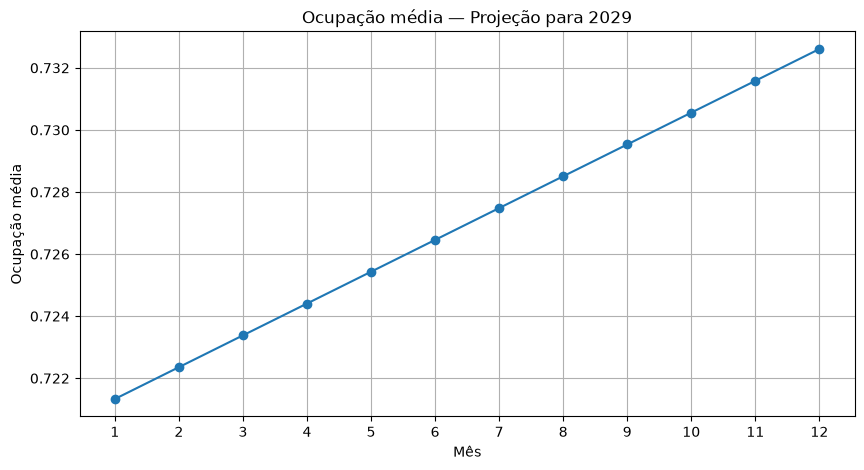

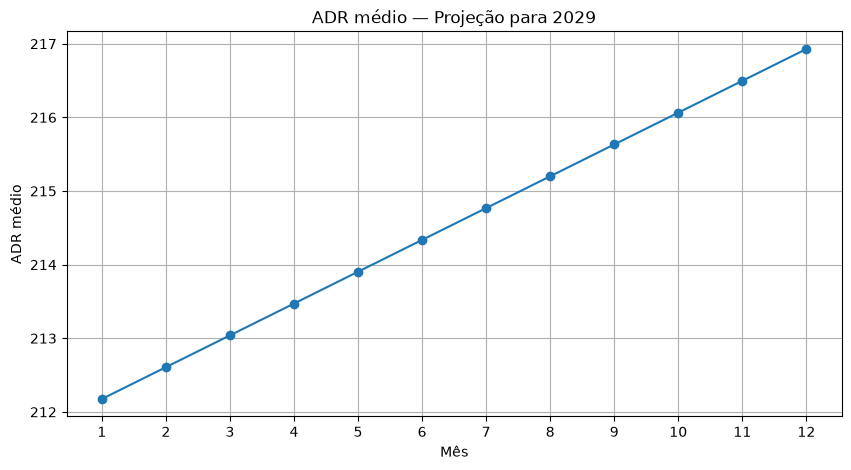

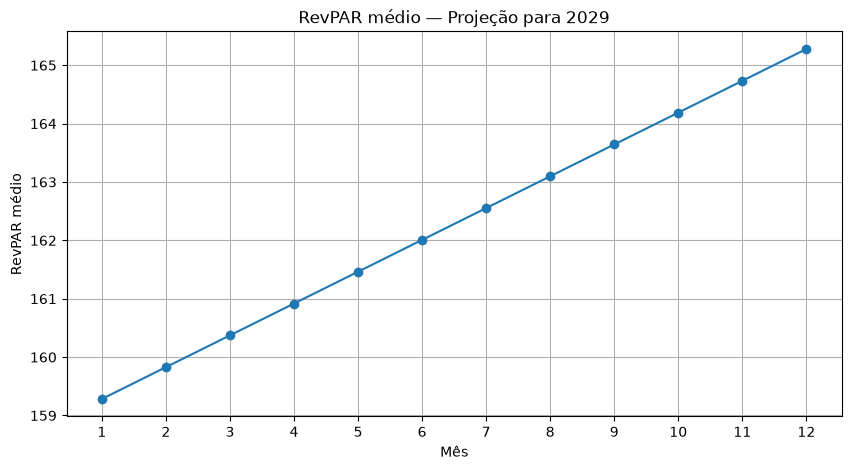

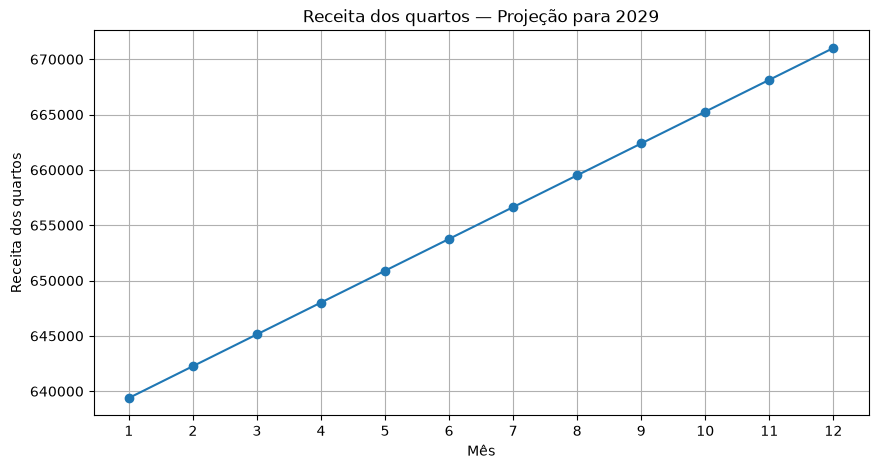

In [14]:
# VISUALIZAÇÃO DAS PROJEÇÕES PARA 2029

import matplotlib.pyplot as plt

nomes_indicadores = {
    "ocupacao_media": "Ocupação média",
    "adr_medio": "ADR médio",
    "revpar_medio": "RevPAR médio",
    "receita_quartos": "Receita dos quartos"
}

for indicador, nome in nomes_indicadores.items():

    dados_grafico = (
        projecao_2029[
            projecao_2029["indicador"] == indicador
        ]
        .groupby("mes")["valor_projetado"]
        .mean()
    )

    plt.figure(figsize=(10, 5))
    plt.plot(
        dados_grafico.index,
        dados_grafico.values,
        marker="o"
    )

    plt.title(f"{nome} — Projeção para 2029")
    plt.xlabel("Mês")
    plt.ylabel(nome)
    plt.xticks(range(1, 13))
    plt.grid(True)
    plt.show()